In [1]:

from google.colab import files

uploaded = files.upload()


Saving BI - Copy.zip to BI - Copy.zip


In [2]:

import zipfile
import os

zip_name = "BI - Copy.zip"
extract_path = "/content/BI_Project"

with zipfile.ZipFile(zip_name, "r") as zip_ref:
    zip_ref.extractall(extract_path)

print("Project extracted successfully!")
print("Project location:", extract_path)
print("Files:", os.listdir(extract_path))


Project extracted successfully!
Project location: /content/BI_Project
Files: ['BI - Copy']


In [3]:

import os

for root, dirs, files_list in os.walk("/content/BI_Project"):
    level = root.replace("/content/BI_Project", "").count(os.sep)

    if level > 3:
        dirs[:] = []
        continue

    indent = "    " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files_list:
        print(f"{indent}    {file}")


BI_Project/
    BI - Copy/
        time-series-forecasting-c3/
            RecommendedCitation.bib
            2_stationarity_and_returns.ipynb
            3_classical_forecasting_baselines.ipynb
            7_multi_horizon_forecast_and_power_bi_export.ipynb
            9_fourier_transform_optional.ipynb
            4_multivariate_machine_learning_forecasting.ipynb
            .gitattributes
            .gitignore
            download_data.py
            5_neural_networks_from_first_principles.ipynb
            LICENSE
            lab_submission_instructions.md
            6_neural_networks_for_stock_forecasting.ipynb
            8_nairobi_securities_exchange_example.ipynb
            README.md
            1_market_data_and_candlesticks.ipynb
            tslab/
                plots.py
                metrics.py
                validation.py
                features.py
                nnutils.py
                __init__.py
                data.py
                config.py
            a

In [5]:

import os
import sys
import subprocess

PROJECT = "/content/BI_Project/BI - Copy/time-series-forecasting-c3"

# Install the project's Colab-specific requirements
subprocess.check_call([
    sys.executable, "-m", "pip", "install", "-q",
    "-r", os.path.join(PROJECT, "requirements", "colab.txt")
])

# Make the project modules accessible
sys.path.insert(0, PROJECT)

print("Installation completed!")
print("Project path:", PROJECT)


Installation completed!
Project path: /content/BI_Project/BI - Copy/time-series-forecasting-c3


In [6]:

from tslab import config, features, validation, metrics

print("PROJECT CHECK: SUCCESS")
print("Selected stock:", config.TARGET_TICKER)
print("Number of predictors:", len(features.ALL_FEATURES))
print("Initial training size:", config.INITIAL_TRAIN)
print("Test block size:", config.TEST_SIZE)


PROJECT CHECK: SUCCESS
Selected stock: KO
Number of predictors: 47
Initial training size: 1000
Test block size: 63


In [7]:

import nbformat

notebook_path = os.path.join(
    PROJECT,
    "4_multivariate_machine_learning_forecasting.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("NOTEBOOK:", notebook_path)
print("TOTAL CELLS:", len(nb.cells))

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "markdown":
        content = cell.source.strip().replace("\n", " ")
        if content:
            print(f"\nCELL {i}: {content[:250]}")


NOTEBOOK: /content/BI_Project/BI - Copy/time-series-forecasting-c3/4_multivariate_machine_learning_forecasting.ipynb
TOTAL CELLS: 66

CELL 0: # Forecasting With Many Predictors: Ridge Regression and Gradient Boosting

CELL 1: | Key              | Value | |:-----------------|:------| | **Course Codes** | BBT 4206 and BFS 4102 | | **Course Names** | BBT 4206: Business Intelligence II (Week 7-9 of 13)<br>BFS 4102: Advanced Business Data Analytics (Week 1-3 of 13) | | **Semes

CELL 2: ## What you will learn in this notebook  By the end of this notebook you should be able to:  1. Build a table of **many predictors** (the stock's own history, volatility, technical indicators, volume, and other markets) for forecasting the next-day r

CELL 3: ## The Narrative  In Notebook 3 the classical models used the stock's own past and, in the last case, seven other markets. They had very little to work with, and they could only combine the inputs **linearly**.  Here we give the model a much richer d

CE


RUNNING NOTEBOOK CELL 6

RUNNING NOTEBOOK CELL 8
Loaded 2981 trading days of KO, 2015-01-02 to 2026-11-09, with 7 predictor series.
Rows in the modelling table: 2781
Number of predictors       : 47
First day                  : 2015-10-16
Last day with a known target: 2026-11-06

RUNNING NOTEBOOK CELL 9


,Number of features,Examples
returns,9,"ret_lag1, ret_lag2, ret_lag3, ret_lag4, ..."
volatility,6,"vol_5d, vol_21d, vol_63d, vol_ratio, ..."
technical,9,"rsi_14, macd_hist, bb_percent_b, bb_width, ..."
volume,1,volume_rel_20d
other_markets,15,"SP500_ret_1d, SP500_ret_5d, TECH_ret_1d, TECH_..."
calendar,7,"is_mon, is_tue, is_wed, is_thu, ..."



RUNNING NOTEBOOK CELL 11


,close,target_return,target_close
Date,,,
2026-11-04,95.800003,-0.000731,95.730003
2026-11-05,95.730003,-0.000627,95.669998
2026-11-06,95.669998,0.003756,96.029999



RUNNING NOTEBOOK CELL 13
PASSED: none of the features changes when the future is removed.

RUNNING NOTEBOOK CELL 20
Number of folds: 29


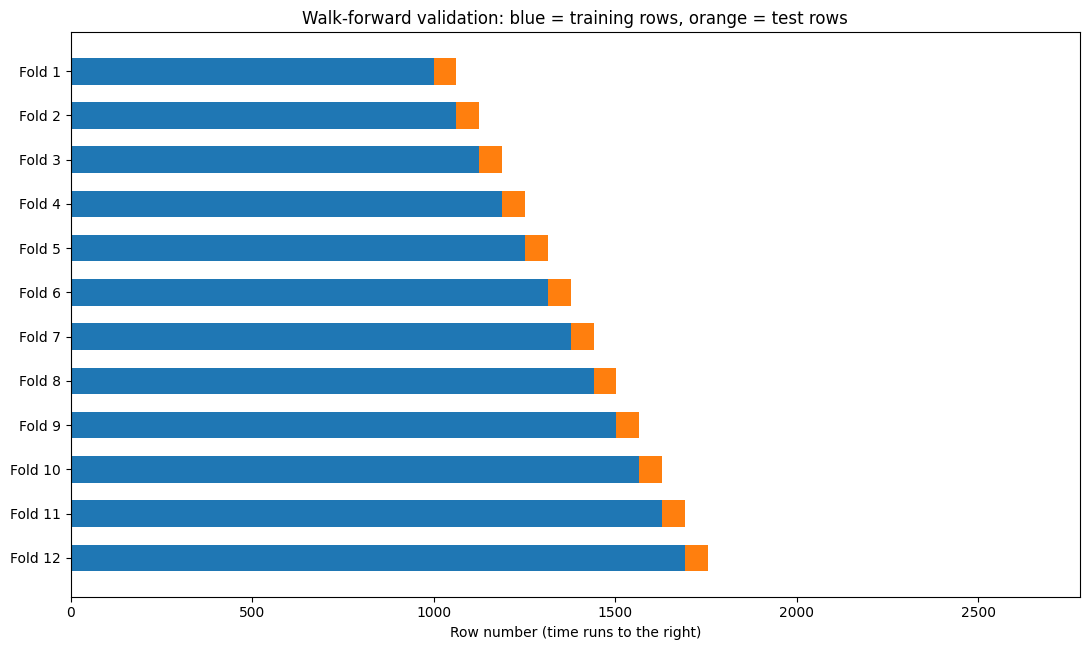


RUNNING NOTEBOOK CELL 21


,train_rows,train_from,train_to,test_rows,test_from,test_to
fold,,,,,,
27,2638,2015-10-16,2026-04-15,63,2026-04-16,2026-07-16
28,2701,2015-10-16,2026-07-16,63,2026-07-17,2026-10-14
29,2764,2015-10-16,2026-10-14,17,2026-10-15,2026-11-06



RUNNING NOTEBOOK CELL 25
Tuning folds: 5 (all inside the first 1000 days)


,1,10,100,1000,10000,100000
Tuning MSE,0.000119,0.000116,0.000107,0.000102,0.000102,0.000102


Chosen Ridge alpha: 10000

RUNNING NOTEBOOK CELL 27
Tuning took 11 seconds


Tuning MSE
max_depth learning_rate            
2         0.01             0.000102
          0.03             0.000104
3         0.01             0.000103
          0.03             0.000105
5         0.01             0.000104
          0.03             0.000108

... (3 outputs left out)

,DM statistic vs naive,DM p-value,Verdict,Hit rate,Hit rate p-value (vs 50%)
Model,,,,,
Ridge,-0.2664,0.7900,No significant difference,0.5087,0.4772
Gradient boosting,1.8733,0.0612,No significant difference,0.5093,0.4483



RUNNING NOTEBOOK CELL 40
R2 with ALL features: 0.00145


,R2 using ONLY this group,R2 WITHOUT this group
Group,,
returns,0.00201,0.00071
volatility,0.00049,0.00146
technical,0.00100,0.00160
volume,0.00070,0.00154
other_markets,0.00073,0.00146
calendar,0.00083,0.00150



RUNNING NOTEBOOK CELL 41


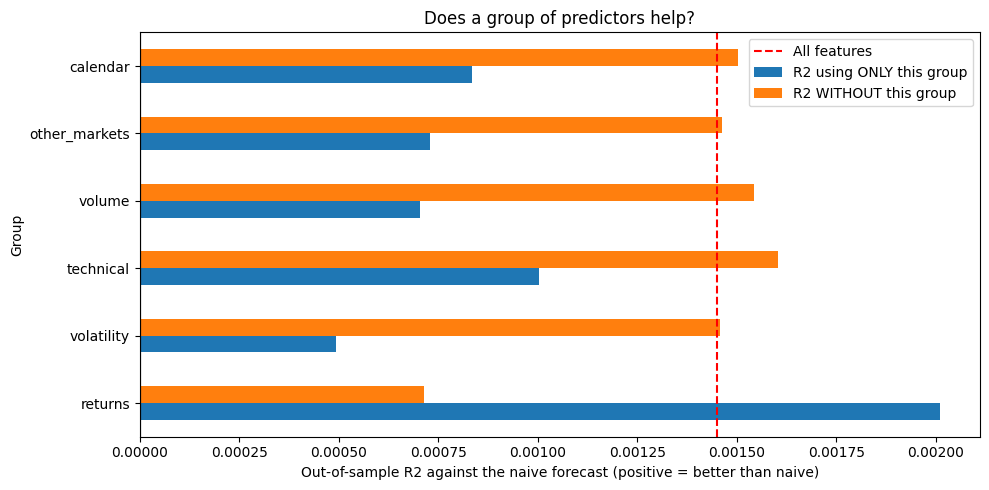


RUNNING NOTEBOOK CELL 43
R2 with ALL features (gradient boosting): -0.01104


,R2 using ONLY this group,R2 WITHOUT this group
Group,,
returns,-0.00430,-0.01218
volatility,-0.00947,-0.01087
technical,-0.00703,-0.00609
volume,-0.00040,-0.01131
other_markets,-0.00527,-0.00793
calendar,-0.00439,-0.01129



RUNNING NOTEBOOK CELL 44


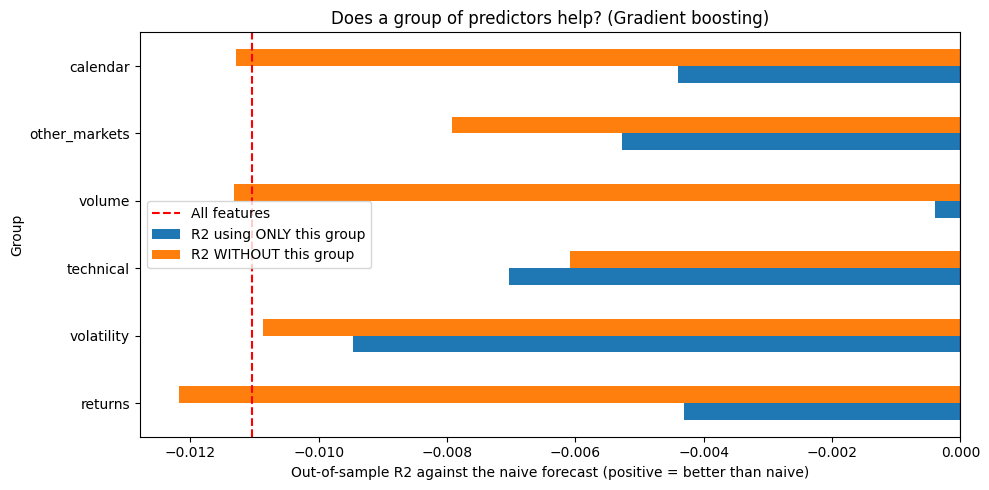


RUNNING NOTEBOOK CELL 46


Ridge                        \
              R2 using ONLY this group R2 WITHOUT this group   
Group                                                          
returns                        0.00201               0.00071   
volatility                     0.00049               0.00146   
technical                      0.00100               0.00160   
volume                         0.00070               0.00154   
other_markets                  0.00073               0.00146   
calendar                       0.00083               0.00150   

                     Gradient boosting                        
              R2 using ONLY this group R2 WITHOUT this group  
Group                                                         
returns                       -0.00430              -0.01218  
volatility                    -0.00947              -0.01087  
technical                     -0.00703              -0.00609  
volume                        -0.00040              -0.01131  
other_markets                 -0.00527              -0.00793  
calendar                      -0.00439              -0.01129


ROLE 4 EXPERIMENTS COMPLETED!


In [8]:

import os
import nbformat
from IPython import get_ipython

# Use our uploaded project
os.chdir(PROJECT)

# Load the original Notebook 4
nb = nbformat.read(notebook_path, as_version=4)

# Run only the cells needed for Role 4
role4_cells = [
    6, 8, 9, 11, 13, 20, 21,  # Setup and validation
    25, 27,                    # Model tuning
    30, 31, 33,                # ML evaluation and DM tests
    40, 41, 43, 44, 46         # Feature group ablation
]

ip = get_ipython()

for cell_number in role4_cells:
    print(f"\n{'='*50}")
    print(f"RUNNING NOTEBOOK CELL {cell_number}")
    print('='*50)

    result = ip.run_cell(nb.cells[cell_number].source)

    if result.error_before_exec or result.error_in_exec:
        raise RuntimeError(
            f"Notebook execution failed at cell {cell_number}. "
            "Check the error displayed above."
        )

print("\nROLE 4 EXPERIMENTS COMPLETED!")


In [9]:
print("Available variables from the experiments:\n")

for name, value in sorted(globals().copy().items()):
    if any(word in name.lower() for word in [
        "ridge", "boost", "ablation", "dm", "result", "metric"
    ]):
        if not name.startswith("_"):
            print(name, ":", type(value).__name__)

Available variables from the experiments:

HistGradientBoostingRegressor : ABCMeta
Ridge : ABCMeta
ablation : DataFrame
ablation_gb : DataFrame
boost_results : dict
boost_table : DataFrame
boosting_factory : function
dm_verdict : function
make_boosting : function
metrics : module
p_dm : float
result : ExecutionResult
ridge_results : dict


In [10]:

from IPython.display import display

print("=" * 60)
print("1. RIDGE REGRESSION RESULTS")
print("=" * 60)

print(ridge_results)

print("\n" + "=" * 60)
print("2. GRADIENT BOOSTING RESULTS")
print("=" * 60)

print(boost_results)

print("\n" + "=" * 60)
print("3. GRADIENT BOOSTING METRICS TABLE")
print("=" * 60)

display(boost_table)

print("\n" + "=" * 60)
print("4. RIDGE FEATURE GROUP ABLATION")
print("=" * 60)

display(ablation)

print("\n" + "=" * 60)
print("5. GRADIENT BOOSTING FEATURE GROUP ABLATION")
print("=" * 60)

display(ablation_gb)

print("\n" + "=" * 60)
print("6. DM TEST P-VALUE")
print("=" * 60)

print("DM p-value:", p_dm)


1. RIDGE REGRESSION RESULTS
{1: 0.00011868030105565483, 10: 0.0001155039695119437, 100: 0.00010745942868346548, 1000: 0.00010168034255673655, 10000: 0.00010160064484569941, 100000: 0.0001020636103747062}

2. GRADIENT BOOSTING RESULTS
{(2, 0.01): 0.00010242519202185063, (2, 0.03): 0.000104158800591012, (3, 0.01): 0.00010268841863803993, (3, 0.03): 0.00010498921554187399, (5, 0.01): 0.00010404454732714156, (5, 0.03): 0.00010750819791824451}

3. GRADIENT BOOSTING METRICS TABLE


Tuning MSE
max_depth learning_rate            
2         0.01             0.000102
          0.03             0.000104
3         0.01             0.000103
          0.03             0.000105
5         0.01             0.000104
          0.03             0.000108


4. RIDGE FEATURE GROUP ABLATION


,R2 using ONLY this group,R2 WITHOUT this group
Group,,
returns,0.002010,0.000714
volatility,0.000492,0.001457
technical,0.001003,0.001603
volume,0.000704,0.001542
other_markets,0.000730,0.001464
calendar,0.000835,0.001502



5. GRADIENT BOOSTING FEATURE GROUP ABLATION


,R2 using ONLY this group,R2 WITHOUT this group
Group,,
returns,-0.004302,-0.012177
volatility,-0.009466,-0.010875
technical,-0.007027,-0.006090
volume,-0.000401,-0.011315
other_markets,-0.005265,-0.007927
calendar,-0.004393,-0.011292



6. DM TEST P-VALUE
DM p-value: 0.06118685284265224


In [12]:
print("FINAL MODEL EVALUATION")
print("=" * 50)

for name in ["ridge_table", "ridge_metrics", "boost_table",
             "ridge_predictions", "boost_predictions",
             "ml_results", "results_table"]:
    if name in globals():
        print(f"\n{name}:")
        print(globals()[name])

print("\nDM TEST SOURCE CODE")
print("=" * 50)

for i in range(29, 35):
    print(f"\n--- CELL {i} ---")
    print(nb.cells[i].source)

FINAL MODEL EVALUATION

boost_table:
                         Tuning MSE
max_depth learning_rate            
2         0.01             0.000102
          0.03             0.000104
3         0.01             0.000103
          0.03             0.000105
5         0.01             0.000104
          0.03             0.000108

DM TEST SOURCE CODE

--- CELL 29 ---
## Step 7: Walk-Forward Test

Now the real test. For every fold, a **new** model is fitted on all the history so far and used to predict the next 63 days. The settings are the frozen ones from Step 6.

--- CELL 30 ---
predictions = {}

started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
print(f"Ridge finished in {time.time() - started:.1f} seconds")

started = time.time()
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits)
print(f"Gradient boosting finished in {time.time() - sta

In [11]:

print("FINAL MODEL EVALUATION VARIABLES")
print("=" * 55)

for name, value in sorted(globals().copy().items()):
    if hasattr(value, "columns") and hasattr(value, "shape"):
        print(f"\n{name}: {value.shape}")
        display(value)

print("\nDM TEST CODE")
print("=" * 55)

for i in range(29, 35):
    print(f"\n--- NOTEBOOK CELL {i} ---")
    print(nb.cells[i].source)


FINAL MODEL EVALUATION VARIABLES

X: (2781, 47)


,ret_lag1,ret_lag2,ret_lag3,ret_lag4,ret_lag5,ret_5d,ret_10d,ret_21d,ret_63d,vol_5d,...,US10Y_level,US10Y_change_5d,relative_to_SP500_5d,is_mon,is_tue,is_wed,is_thu,is_fri,month_sin,month_cos
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16,0.002383,0.005742,0.000720,-0.008368,-0.000476,0.000000,0.039564,0.064888,0.023974,0.005230,...,2.023,-0.076,-0.009002,0.0,0.0,0.0,0.0,1.0,-0.866025,0.500000
2015-10-19,-0.000714,0.002383,0.005742,0.000720,-0.008368,-0.000238,0.023615,0.074383,0.027862,0.005236,...,2.028,-0.062,-0.008236,1.0,0.0,0.0,0.0,0.0,-0.866025,0.500000
2015-10-20,0.007119,-0.000714,0.002383,0.005742,0.000720,0.015249,0.031954,0.076129,0.042047,0.003311,...,2.071,0.016,0.001824,0.0,1.0,0.0,0.0,0.0,-0.866025,0.500000
2015-10-21,-0.002367,0.007119,-0.000714,0.002383,0.005742,0.012162,0.016008,0.084021,0.041148,0.004058,...,2.030,0.049,-0.000148,0.0,0.0,1.0,0.0,0.0,-0.866025,0.500000
2015-10-22,0.024583,-0.002367,0.007119,-0.000714,0.002383,0.031003,0.029573,0.109377,0.075573,0.010892,...,2.025,0.002,0.016946,0.0,0.0,0.0,1.0,0.0,-0.866025,0.500000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2026-11-02,0.018430,0.013483,0.011813,0.006014,-0.016533,0.033207,0.025470,0.112307,0.107687,0.013693,...,4.894,-0.092,0.050998,1.0,0.0,0.0,0.0,0.0,-0.500000,0.866025
2026-11-03,-0.010806,0.018430,0.013483,0.011813,0.006014,0.038934,0.013915,0.091509,0.093767,0.011300,...,4.952,-0.041,0.059035,0.0,1.0,0.0,0.0,0.0,-0.500000,0.866025
2026-11-04,0.010493,-0.010806,0.018430,0.013483,0.011813,0.043413,0.033110,0.105941,0.104030,0.011302,...,4.894,-0.151,0.050588,0.0,0.0,1.0,0.0,0.0,-0.500000,0.866025



_: (6, 4)


Ridge                        \
              R2 using ONLY this group R2 WITHOUT this group   
Group                                                          
returns                        0.00201               0.00071   
volatility                     0.00049               0.00146   
technical                      0.00100               0.00160   
volume                         0.00070               0.00154   
other_markets                  0.00073               0.00146   
calendar                       0.00083               0.00150   

                     Gradient boosting                        
              R2 using ONLY this group R2 WITHOUT this group  
Group                                                         
returns                       -0.00430              -0.01218  
volatility                    -0.00947              -0.01087  
technical                     -0.00703              -0.00609  
volume                        -0.00040              -0.01131  
other_markets                 -0.00527              -0.00793  
calendar                      -0.00439              -0.01129


_8: (6, 4)


Ridge                        \
              R2 using ONLY this group R2 WITHOUT this group   
Group                                                          
returns                        0.00201               0.00071   
volatility                     0.00049               0.00146   
technical                      0.00100               0.00160   
volume                         0.00070               0.00154   
other_markets                  0.00073               0.00146   
calendar                       0.00083               0.00150   

                     Gradient boosting                        
              R2 using ONLY this group R2 WITHOUT this group  
Group                                                         
returns                       -0.00430              -0.01218  
volatility                    -0.00947              -0.01087  
technical                     -0.00703              -0.00609  
volume                        -0.00040              -0.01131  
other_markets                 -0.00527              -0.00793  
calendar                      -0.00439              -0.01129

... (19 outputs left out)

,Number of features,Examples
returns,9,"ret_lag1, ret_lag2, ret_lag3, ret_lag4, ..."
volatility,6,"vol_5d, vol_21d, vol_63d, vol_ratio, ..."
technical,9,"rsi_14, macd_hist, bb_percent_b, bb_width, ..."
volume,1,volume_rel_20d
other_markets,15,"SP500_ret_1d, SP500_ret_5d, TECH_ret_1d, TECH_..."
calendar,7,"is_mon, is_tue, is_wed, is_thu, ..."



tuning_X: (1000, 47)


,ret_lag1,ret_lag2,ret_lag3,ret_lag4,ret_lag5,ret_5d,ret_10d,ret_21d,ret_63d,vol_5d,...,US10Y_level,US10Y_change_5d,relative_to_SP500_5d,is_mon,is_tue,is_wed,is_thu,is_fri,month_sin,month_cos
Date,,,,,,,,,,,,,,,,,,,,,
2015-10-16,0.002383,0.005742,0.000720,-0.008368,-0.000476,0.000000,0.039564,0.064888,0.023974,0.005230,...,2.023,-0.076,-0.009002,0.0,0.0,0.0,0.0,1.0,-0.866025,0.5
2015-10-19,-0.000714,0.002383,0.005742,0.000720,-0.008368,-0.000238,0.023615,0.074383,0.027862,0.005236,...,2.028,-0.062,-0.008236,1.0,0.0,0.0,0.0,0.0,-0.866025,0.5
2015-10-20,0.007119,-0.000714,0.002383,0.005742,0.000720,0.015249,0.031954,0.076129,0.042047,0.003311,...,2.071,0.016,0.001824,0.0,1.0,0.0,0.0,0.0,-0.866025,0.5
2015-10-21,-0.002367,0.007119,-0.000714,0.002383,0.005742,0.012162,0.016008,0.084021,0.041148,0.004058,...,2.030,0.049,-0.000148,0.0,0.0,1.0,0.0,0.0,-0.866025,0.5
2015-10-22,0.024583,-0.002367,0.007119,-0.000714,0.002383,0.031003,0.029573,0.109377,0.075573,0.010892,...,2.025,0.002,0.016946,0.0,0.0,0.0,1.0,0.0,-0.866025,0.5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2019-10-01,0.003850,0.002391,-0.001472,0.004053,-0.002397,0.006425,0.007530,0.000174,0.057375,0.003026,...,1.644,0.009,0.015347,0.0,1.0,0.0,0.0,0.0,-0.866025,0.5
2019-10-02,-0.029149,0.003850,0.002391,-0.001472,0.004053,-0.020327,-0.021434,-0.033688,0.025920,0.014197,...,1.596,-0.136,0.012800,0.0,0.0,1.0,0.0,0.0,-0.866025,0.5
2019-10-03,0.014217,-0.029149,0.003850,0.002391,-0.001472,-0.010164,-0.012551,-0.027935,0.039945,0.016231,...,1.536,-0.149,0.012591,0.0,0.0,0.0,1.0,0.0,-0.866025,0.5



DM TEST CODE

--- NOTEBOOK CELL 29 ---
## Step 7: Walk-Forward Test

Now the real test. For every fold, a **new** model is fitted on all the history so far and used to predict the next 63 days. The settings are the frozen ones from Step 6.

--- NOTEBOOK CELL 30 ---
predictions = {}

started = time.time()
predictions["Ridge"] = walk_forward_predict(lambda: Ridge(alpha=best_alpha), X, y, splits)
print(f"Ridge finished in {time.time() - started:.1f} seconds")

started = time.time()
predictions["Gradient boosting"] = walk_forward_predict(
    lambda: make_boosting(max_depth=best_depth, learning_rate=best_rate), X, y, splits)
print(f"Gradient boosting finished in {time.time() - started:.1f} seconds")

--- NOTEBOOK CELL 31 ---
scores = compare_models(dataset, predictions)
scores.round(4)

--- NOTEBOOK CELL 32 ---
Read the table as you did in Notebook 3: compare the RMSE with the naive row first, then the out-of-sample R2, then the directional accuracy.

Now ask whether any gap is **real**. 

In [13]:
scored_rows = pd.concat(predictions, axis=1).dropna().index
actual = dataset.loc[scored_rows, "target_return"]

dm_results = []

for name, series in predictions.items():
    statistic, p_value = diebold_mariano(
        actual,
        series.loc[scored_rows],
        np.zeros(len(scored_rows))
    )

    dm_results.append({
        "Model": name,
        "DM statistic": statistic,
        "DM p-value": p_value,
        "Verdict": dm_verdict(statistic, p_value)
    })

dm_results = pd.DataFrame(dm_results).set_index("Model")
display(dm_results.round(6))

,DM statistic,DM p-value,Verdict
Model,,,
Ridge,-0.266405,0.789958,No significant difference
Gradient boosting,1.873328,0.061187,No significant difference


In [14]:

import os
import subprocess

PROJECT = "/content/BI_Project/BI - Copy/time-series-forecasting-c3"
os.chdir(PROJECT)

def git(command):
    result = subprocess.run(
        ["git"] + command,
        capture_output=True,
        text=True
    )
    print(result.stdout)
    if result.stderr:
        print(result.stderr)

print("CURRENT BRANCH:")
git(["branch", "--show-current"])

print("\nGIT STATUS:")
git(["status"])

print("\nREMOTE REPOSITORIES:")
git(["remote", "-v"])

print("\nCHANGED FILES:")
git(["diff", "--name-only"])

print("\nUNTRACKED FILES:")
git(["ls-files", "--others", "--exclude-standard"])


CURRENT BRANCH:
main


GIT STATUS:
On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   lab_submission_instructions.md

no changes added to commit (use "git add" and/or "git commit -a")


REMOTE REPOSITORIES:
origin	https://github.com/nataliaodhiambo/time-series-forecasting-c3.git (fetch)
origin	https://github.com/nataliaodhiambo/time-series-forecasting-c3.git (push)


CHANGED FILES:
lab_submission_instructions.md


UNTRACKED FILES:



In [15]:

import os
import subprocess

os.chdir(PROJECT)

print("CHANGES TO lab_submission_instructions.md:")
subprocess.run(["git", "diff", "--", "lab_submission_instructions.md"])

notebook = "4_multivariate_machine_learning_forecasting.ipynb"

print("\nNOTEBOOK DETAILS:")
print("Exists:", os.path.exists(notebook))

if os.path.exists(notebook):
    print("File size:", os.path.getsize(notebook), "bytes")

print("\nCURRENT GIT STATUS:")
subprocess.run(["git", "status", "--short"])


CHANGES TO lab_submission_instructions.md:

NOTEBOOK DETAILS:
Exists: True
File size: 62925 bytes

CURRENT GIT STATUS:


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [16]:

import os
import subprocess

os.chdir(PROJECT)

print("1. SUMMARY OF CHANGES")
subprocess.run(["git", "diff", "--stat"])

print("\n2. CHANGES TO SUBMISSION INSTRUCTIONS")
subprocess.run(["git", "diff", "--", "lab_submission_instructions.md"])

print("\n3. NOTEBOOK TRACKING STATUS")
notebook = "4_multivariate_machine_learning_forecasting.ipynb"

print("Notebook exists:", os.path.exists(notebook))

subprocess.run(["git", "ls-files", "--error-unmatch", notebook])

print("\n4. CURRENT GIT STATUS")
subprocess.run(["git", "status", "--short"])


1. SUMMARY OF CHANGES

2. CHANGES TO SUBMISSION INSTRUCTIONS

3. NOTEBOOK TRACKING STATUS
Notebook exists: True

4. CURRENT GIT STATUS


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [17]:

import nbformat
import os

notebook_path = os.path.join(
    PROJECT,
    "4_multivariate_machine_learning_forecasting.ipynb"
)

nb = nbformat.read(notebook_path, as_version=4)

print("TOTAL CELLS:", len(nb.cells))

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code" and cell.get("outputs"):
        output_text = "\n".join(
            str(out.get("text", ""))
            for out in cell.outputs
        )

        if any(term in output_text.lower() for term in [
            "ridge", "gradient boosting", "ablation",
            "dm statistic", "dm p-value"
        ]):
            print(f"\nCELL {i}:")
            print(output_text[:1500])


TOTAL CELLS: 66


In [18]:

import os
import subprocess

os.chdir(PROJECT)

subprocess.run(["git", "status", "--short"])


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [19]:
from google.colab import files

uploaded = files.upload()

Saving Untitled1.ipynb to Untitled1.ipynb


In [20]:
import os
import shutil
import subprocess

os.chdir(PROJECT)

uploaded_name = next(iter(uploaded))

destination = os.path.join(
    PROJECT,
    "4_multivariate_machine_learning_forecasting.ipynb"
)

shutil.copy2(uploaded_name, destination)

print("Notebook copied successfully:", os.path.exists(destination))

subprocess.run(["git", "status", "--short"])

Notebook copied successfully: True


CompletedProcess(args=['git', 'status', '--short'], returncode=0)

In [21]:
import nbformat
import os

path = os.path.join(
    PROJECT,
    "4_multivariate_machine_learning_forecasting.ipynb"
)

nb = nbformat.read(path, as_version=4)

for i, cell in enumerate(nb.cells):
    if cell.cell_type == "code" and cell.get("outputs"):
        output = "\n".join(
            str(o.get("text", ""))
            for o in cell.outputs
        )

        if output.strip():
            print(f"\nCELL {i}:")
            print(output[:1000])


CELL 0:

Saving BI - Copy.zip to BI - Copy.zip


CELL 1:
Project extracted successfully!
Project location: /content/BI_Project
Files: ['BI - Copy']


CELL 2:
BI_Project/
    BI - Copy/
        time-series-forecasting-c3/
            RecommendedCitation.bib
            2_stationarity_and_returns.ipynb
            3_classical_forecasting_baselines.ipynb
            7_multi_horizon_forecast_and_power_bi_export.ipynb
            9_fourier_transform_optional.ipynb
            4_multivariate_machine_learning_forecasting.ipynb
            .gitattributes
            .gitignore
            download_data.py
            5_neural_networks_from_first_principles.ipynb
            LICENSE
            lab_submission_instructions.md
            6_neural_networks_for_stock_forecasting.ipynb
            8_nairobi_securities_exchange_example.ipynb
            README.md
            1_market_data_and_candlesticks.ipynb
            tslab/
                plots.py
                metrics.py
                v

In [22]:
import os
import subprocess
import hashlib

os.chdir(PROJECT)

notebook = "4_multivariate_machine_learning_forecasting.ipynb"

def get_hash(path):
    with open(path, "rb") as f:
        return hashlib.sha256(f.read()).hexdigest()

local_hash = get_hash(notebook)

remote_result = subprocess.run(
    ["git", "show", f"origin/main:{notebook}"],
    capture_output=True
)

print("LOCAL NOTEBOOK HASH:", local_hash)

if remote_result.returncode == 0:
    remote_hash = hashlib.sha256(remote_result.stdout).hexdigest()
    print("GITHUB NOTEBOOK HASH:", remote_hash)
    print("IDENTICAL:", local_hash == remote_hash)
else:
    print("Notebook not found on origin/main.")
    print(remote_result.stderr.decode())

LOCAL NOTEBOOK HASH: 94168e89cc40a87e03ea17f409c0b85c7bad1a1d23d924bf5888903f80a4c261
GITHUB NOTEBOOK HASH: 742b2f3bce64068a4a5b1f47ffc0e58d378e4b4647af2875aaf7d561cebb26fa
IDENTICAL: False


In [23]:
import os
import subprocess

os.chdir(PROJECT)

print("GIT STATUS:")
subprocess.run(["git", "status", "--short"])

print("\nNOTEBOOK DIFFERENCE:")
subprocess.run([
    "git", "diff", "--stat", "--",
    "4_multivariate_machine_learning_forecasting.ipynb"
])

print("\nCURRENT BRANCH:")
subprocess.run(["git", "branch", "--show-current"])

GIT STATUS:

NOTEBOOK DIFFERENCE:

CURRENT BRANCH:


CompletedProcess(args=['git', 'branch', '--show-current'], returncode=0)

In [24]:
import os
import subprocess

os.chdir(PROJECT)

print("PROJECT:", os.getcwd())

print("GIT ROOT:")
subprocess.run(["git", "rev-parse", "--show-toplevel"])

print("NOTEBOOK PATH:")
print(os.path.abspath("4_multivariate_machine_learning_forecasting.ipynb"))

print("TRACKED FILE:")
subprocess.run([
    "git", "ls-files", "-v",
    "4_multivariate_machine_learning_forecasting.ipynb"
])

print("IGNORED STATUS:")
subprocess.run([
    "git", "check-ignore", "-v",
    "4_multivariate_machine_learning_forecasting.ipynb"
])

print("STATUS:")
subprocess.run(["git", "status", "--short", "--untracked-files=all"])

PROJECT: /content/BI_Project/BI - Copy/time-series-forecasting-c3
GIT ROOT:
NOTEBOOK PATH:
/content/BI_Project/BI - Copy/time-series-forecasting-c3/4_multivariate_machine_learning_forecasting.ipynb
TRACKED FILE:
IGNORED STATUS:
STATUS:


CompletedProcess(args=['git', 'status', '--short', '--untracked-files=all'], returncode=0)

In [25]:
import os

for root, dirs, files in os.walk("/content/BI_Project"):
    dirs[:] = [d for d in dirs if d not in [".ipynb_checkpoints"]]

    if ".git" in dirs:
        print("GIT REPOSITORY FOUND:", root)

GIT REPOSITORY FOUND: /content/BI_Project/BI - Copy/time-series-forecasting-c3


In [26]:
import os
import subprocess

os.chdir(PROJECT)

for command in [
    ["git", "rev-parse", "--git-dir"],
    ["git", "rev-parse", "--show-toplevel"],
    ["git", "status"],
    ["git", "ls-files", "4_multivariate_machine_learning_forecasting.ipynb"],
    ["git", "config", "--get", "core.sparseCheckout"]
]:
    result = subprocess.run(command, capture_output=True, text=True)
    print("\nCOMMAND:", " ".join(command))
    print("RETURN CODE:", result.returncode)
    print("OUTPUT:", result.stdout)
    print("ERROR:", result.stderr)


COMMAND: git rev-parse --git-dir
RETURN CODE: 0
OUTPUT: .git

ERROR: 

COMMAND: git rev-parse --show-toplevel
RETURN CODE: 0
OUTPUT: /content/BI_Project/BI - Copy/time-series-forecasting-c3

ERROR: 

COMMAND: git status
RETURN CODE: 0
OUTPUT: On branch main
Your branch is up to date with 'origin/main'.

Changes not staged for commit:
  (use "git add <file>..." to update what will be committed)
  (use "git restore <file>..." to discard changes in working directory)
	modified:   4_multivariate_machine_learning_forecasting.ipynb
	modified:   lab_submission_instructions.md

Untracked files:
  (use "git add <file>..." to include in what will be committed)
	Untitled1.ipynb

no changes added to commit (use "git add" and/or "git commit -a")

ERROR: 

COMMAND: git ls-files 4_multivariate_machine_learning_forecasting.ipynb
RETURN CODE: 0
OUTPUT: 4_multivariate_machine_learning_forecasting.ipynb

ERROR: 

COMMAND: git config --get core.sparseCheckout
RETURN CODE: 1
OUTPUT: 
ERROR: 


In [27]:
import os
import subprocess

os.chdir(PROJECT)

subprocess.run([
    "git", "switch", "-c", "role4-ml-ablation"
], check=True)

print("\nCURRENT BRANCH:")
subprocess.run(["git", "branch", "--show-current"])


CURRENT BRANCH:


CompletedProcess(args=['git', 'branch', '--show-current'], returncode=0)

In [30]:
import os
import subprocess

os.chdir(PROJECT)

subprocess.run(["git", "config", "user.name", "TeddMK"])
subprocess.run(["git", "config", "user.email", "tedd.kisese@strathmore.edu"])

print("Git identity configured.")

Git identity configured.


In [31]:
import subprocess

result = subprocess.run(
    ["git", "commit", "-m",
     "Complete Role 4: ML models, feature ablation and DM testing"],
    capture_output=True,
    text=True
)

print("OUTPUT:", result.stdout)
print("ERROR:", result.stderr)
print("RETURN CODE:", result.returncode)

OUTPUT: [role4-ml-ablation 6dbcf18] Complete Role 4: ML models, feature ablation and DM testing
 1 file changed, 8498 insertions(+), 1351 deletions(-)

ERROR: 
RETURN CODE: 0


In [32]:
import os
import subprocess

os.chdir(PROJECT)

result = subprocess.run(
    ["git", "push", "-u", "origin", "role4-ml-ablation"],
    capture_output=True,
    text=True
)

print("OUTPUT:", result.stdout)
print("ERROR:", result.stderr)
print("RETURN CODE:", result.returncode)

OUTPUT: 
ERROR: fatal: could not read Username for 'https://github.com': No such device or address

RETURN CODE: 128
